# Machine Learning for Network Analysis Activity - Bruno Cavagnaro

**GRAD 50800 - Data Analytics**

**Objective:** use the distance measures behind clustering, and graph-centrality measures, to analyze network behavior.

| Question | Topic | Section |
|---|---|---|
| 1 | Euclidean and Manhattan distance formulas | 1 |
| 2 | Euclidean and Manhattan distance between (25, 20) and (40, 30) | 2 |
| 3 | Degree, closeness and betweenness for the 10-node graph | 3 |
| 4 | Personal social network: remove my node and rank the rest by degree and closeness | 4 |

## 0. Requirements

| Library | Used for | Minimum version |
|---|---|---|
| `networkx` | building graphs; degree, closeness and betweenness centrality; shortest paths; drawing graphs | 3.0 |
| `scipy` | `scipy.spatial.distance` (Euclidean and cityblock distances); also needed by some `networkx` layouts | 1.10 |
| `numpy` | arrays and numeric work | 1.24 |
| `pandas` | result tables | 2.0 |
| `matplotlib` | all figures | 3.7 |

`numpy`, `pandas`, `scipy` and `matplotlib` are already in this course project (`pyproject.toml`). **`networkx` is the only new dependency.** Install it from a terminal in the course folder using **one** of these options:

```bash
# Option A - uv (this project uses uv + pyproject.toml)
uv add networkx

# Option B - pip, inside the activated .venv
pip install "networkx>=3.0" "scipy>=1.10"
```

Then restart the Jupyter kernel. The next cell installs `networkx` automatically if it is missing, and prints the version of every library.

In [1]:
import importlib, subprocess, sys

for pkg in ["networkx", "scipy", "numpy", "pandas", "matplotlib"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        print(f"Installing {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import networkx as nx
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.spatial import distance

for m in [nx, scipy, np, pd, matplotlib]:
    print(f"{m.__name__:<11} {m.__version__}")
print("Python     ", sys.version.split()[0])
pd.set_option("display.precision", 4)

networkx    3.7
scipy       1.18.1
numpy       2.5.4
pandas      3.1.0
matplotlib  3.11.2
Python      3.12.14


---
## 1. Distance formulas

> Using the following figure and its labeled coordinates (X₁, X₂, Y₁, and Y₂), provide the equations for Euclidean and Manhattan distances, respectively.

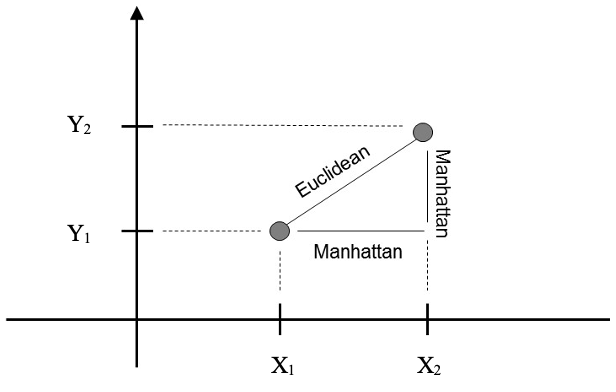


For two points $P_1 = (X_1, Y_1)$ and $P_2 = (X_2, Y_2)$:

**Euclidean distance**, the straight line ("as the crow flies") between the points:

$$
d_{\text{Euclidean}}(P_1, P_2) = \sqrt{(X_2 - X_1)^2 + (Y_2 - Y_1)^2}
$$

*Plain text:* `Euclidean = sqrt((X2 - X1)^2 + (Y2 - Y1)^2)`

**Manhattan (city-block) distance**, which moves only horizontally and vertically, like walking the streets of a grid:

$$
d_{\text{Manhattan}}(P_1, P_2) = |X_2 - X_1| + |Y_2 - Y_1|
$$

*Plain text:* `Manhattan = |X2 - X1| + |Y2 - Y1|`

Both are special cases of the **Minkowski distance** $d_p = \left(|X_2 - X_1|^p + |Y_2 - Y_1|^p\right)^{1/p}$, with $p = 2$ (Euclidean) and $p = 1$ (Manhattan). By the triangle inequality, Manhattan distance is always greater than or equal to Euclidean distance. The two are equal only when the points share an X or a Y coordinate.

---
## 2. Actual distances

> Using the preceding figure, provide the actual Euclidean and Manhattan distances, respectively.

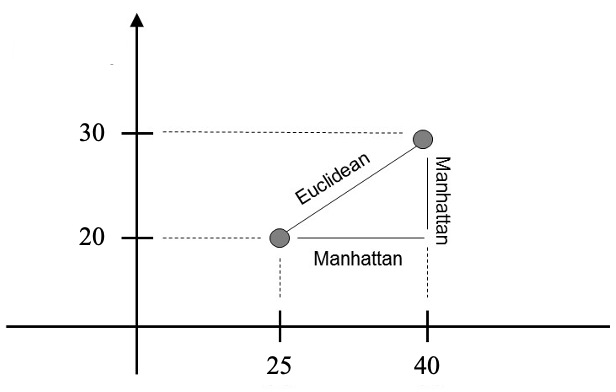


From the figure: $P_1 = (25, 20)$ and $P_2 = (40, 30)$, so $\Delta X = 40 - 25 = 15$ and $\Delta Y = 30 - 20 = 10$.

$$
d_{\text{Euclidean}} = \sqrt{15^2 + 10^2} = \sqrt{225 + 100} = \sqrt{325} = 5\sqrt{13} \approx \mathbf{18.03}
$$

$$
d_{\text{Manhattan}} = |15| + |10| = \mathbf{25}
$$

The next cell checks both results three ways: by the formula, with `scipy.spatial.distance`, and with `numpy`.

In [2]:
p1 = np.array([25, 20])
p2 = np.array([40, 30])

euclid_formula = np.sqrt((p2[0] - p1[0]) ** 2 + (p2[1] - p1[1]) ** 2)
manhattan_formula = abs(p2[0] - p1[0]) + abs(p2[1] - p1[1])

results = pd.DataFrame({
    "formula": [euclid_formula, manhattan_formula],
    "scipy.spatial.distance": [distance.euclidean(p1, p2), distance.cityblock(p1, p2)],
    "numpy.linalg.norm": [np.linalg.norm(p2 - p1, ord=2), np.linalg.norm(p2 - p1, ord=1)],
}, index=["Euclidean", "Manhattan"])
results.round(4)

,formula,scipy.spatial.distance,numpy.linalg.norm
Euclidean,18.0278,18.0278,18.0278
Manhattan,25.0000,25.0000,25.0000


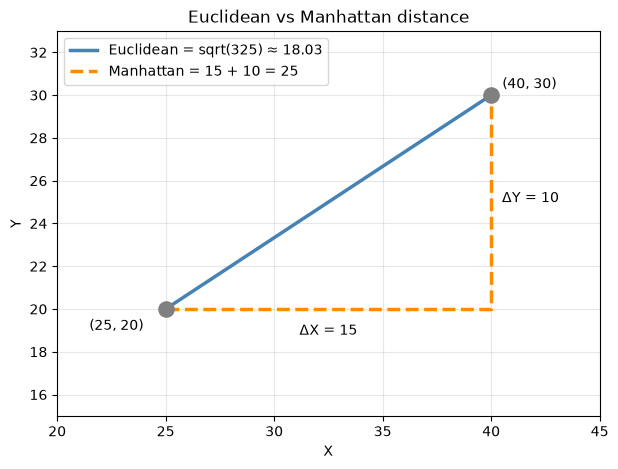

In [3]:
# Recreate the figure from the activity, showing both paths
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(*zip(p1, p2), "-", color="steelblue", lw=2.5, label=f"Euclidean = sqrt(325) ≈ {euclid_formula:.2f}")
ax.plot([p1[0], p2[0], p2[0]], [p1[1], p1[1], p2[1]], "--", color="darkorange", lw=2.5,
        label=f"Manhattan = 15 + 10 = {manhattan_formula}")
ax.scatter(*zip(p1, p2), s=120, color="grey", zorder=3)
ax.annotate("(25, 20)", p1, textcoords="offset points", xytext=(-55, -15))
ax.annotate("(40, 30)", p2, textcoords="offset points", xytext=(8, 5))
ax.text(32.5, 18.8, "ΔX = 15", ha="center"); ax.text(40.5, 25, "ΔY = 10")
ax.set_xlim(20, 45); ax.set_ylim(15, 33); ax.set_xlabel("X"); ax.set_ylabel("Y")
ax.set_title("Euclidean vs Manhattan distance"); ax.legend(loc="upper left"); ax.grid(alpha=.3)
plt.show()

**Why this matters for clustering:** k-means and k-NN depend on the distance measure. Euclidean distance favours compact, round clusters and is sensitive to large differences in a single feature, because those differences are squared. Manhattan distance adds up the absolute differences, so it is more robust to outliers and often works better in high dimensions or on grid-like data. Either way, features should be put on comparable scales first; otherwise, a variable measured in large units dominates the distance.

---
## 3. Degree, closeness and betweenness

> Calculate degree, closeness and betweenness for each of the nodes in the following graph.

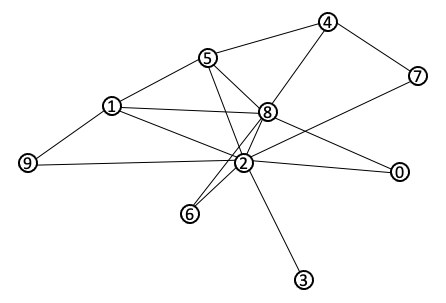


### 3.1 Edge list read from the figure
The undirected graph has **10 nodes and 17 edges**:

| Node | Neighbours |
|---|---|
| 0 | 2, 8 |
| 1 | 2, 5, 8, 9 |
| 2 | 0, 1, 3, 5, 6, 7, 8, 9 |
| 3 | 2 |
| 4 | 5, 7, 8 |
| 5 | 1, 2, 4, 8 |
| 6 | 2, 8 |
| 7 | 2, 4 |
| 8 | 0, 1, 2, 4, 5, 6 |
| 9 | 1, 2 |

The graph is drawn below with node positions copied from the original figure, so the two can be compared edge by edge.

Nodes: 10 | Edges: 17 | Connected: True
Check: sum of degrees = 34 = 2 x edges = 34


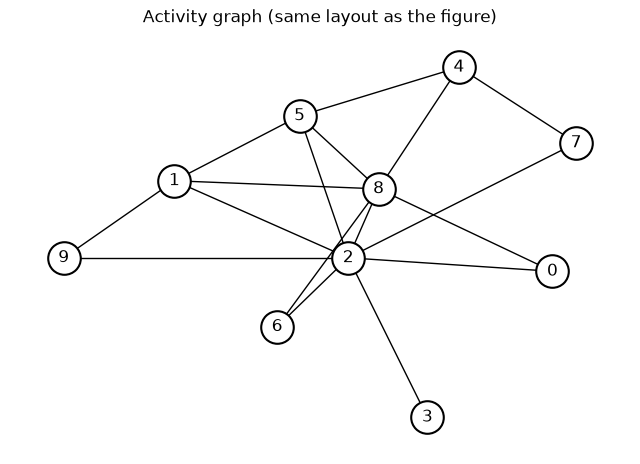

In [4]:
EDGES = [(5, 1), (5, 4), (5, 8), (5, 2), (4, 8), (4, 7), (7, 2), (1, 8), (1, 2),
         (1, 9), (9, 2), (8, 0), (8, 2), (8, 6), (2, 6), (2, 0), (2, 3)]
G = nx.Graph(EDGES)

# Node positions copied from the activity figure (pixel coordinates, with y flipped)
POS = {0: (399, 172), 1: (112, 105), 2: (244, 162), 3: (304, 280), 4: (328, 21),
       5: (207, 57), 6: (190, 213), 7: (417, 77), 8: (267, 111), 9: (28, 162)}
POS = {k: (x, -y) for k, (x, y) in POS.items()}

print(f"Nodes: {G.number_of_nodes()} | Edges: {G.number_of_edges()} | Connected: {nx.is_connected(G)}")
print(f"Check: sum of degrees = {sum(d for _, d in G.degree())} = 2 x edges = {2 * G.number_of_edges()}")

plt.figure(figsize=(8, 5.5))
nx.draw_networkx(G, POS, node_color="white", edgecolors="black", node_size=550, font_size=12, linewidths=1.5)
plt.title("Activity graph (same layout as the figure)"); plt.axis("off"); plt.show()

### 3.2 Definitions

For a connected graph with $n$ nodes ($n = 10$ here):

* **Degree centrality**: the number of edges attached to node $v$, written $\deg(v)$. Normalized degree divides it by the maximum possible, $n - 1 = 9$.
* **Closeness centrality**: how close $v$ is to every other node. It uses the *farness*, the sum of shortest-path distances $\sum_{u} d(v, u)$:
$$C(v) = \frac{n - 1}{\sum_{u \neq v} d(v, u)}$$
This is the normalized version that `networkx` reports. It equals 1 when a node is directly linked to everyone. The raw version is simply $1 / \text{farness}$.
* **Betweenness centrality**: how often $v$ lies on the shortest paths between other pairs of nodes:
$$B(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$$
where $\sigma_{st}$ is the number of shortest paths from $s$ to $t$, and $\sigma_{st}(v)$ is how many of them pass through $v$. When a pair has several shortest paths, the credit is split between them, which is why some values are fractions. Normalized betweenness divides by the number of pairs not involving $v$, $\binom{n-1}{2} = 36$.

### 3.3 Shortest-path distance matrix (the basis for closeness)

In [5]:
dist = pd.DataFrame(dict(nx.all_pairs_shortest_path_length(G))).sort_index().sort_index(axis=1)
dist.index.name, dist.columns.name = "from", "to"
display(dist)
print("Farness (row sums):", dist.sum(axis=1).to_dict())

to,0,1,2,3,4,5,6,7,8,9
from,,,,,,,,,,
0,0,2,1,2,2,2,2,2,1,2
1,2,0,1,2,2,1,2,2,1,1
2,1,1,0,1,2,1,1,1,1,1
3,2,2,1,0,3,2,2,2,2,2
4,2,2,2,3,0,1,2,1,1,3
5,2,1,1,2,1,0,2,2,1,2
6,2,2,1,2,2,2,0,2,1,2
7,2,2,1,2,1,2,2,0,2,2
8,1,1,1,2,1,1,1,2,0,2


Farness (row sums): {0: 16, 1: 14, 2: 10, 3: 18, 4: 17, 5: 14, 6: 16, 7: 16, 8: 12, 9: 17}


### 3.4 Answer table

In [6]:
n = G.number_of_nodes()
farness = dist.sum(axis=1)

table = pd.DataFrame({
    "Degree": dict(G.degree()),
    "Degree (normalized)": nx.degree_centrality(G),
    "Farness (sum of distances)": farness,
    "Closeness": nx.closeness_centrality(G),                 # (n-1) / farness
    "Closeness (raw 1/farness)": 1 / farness,
    "Betweenness": nx.betweenness_centrality(G, normalized=False),
    "Betweenness (normalized)": nx.betweenness_centrality(G, normalized=True),
}).sort_index()
table.index.name = "Node"

# Sanity check: networkx closeness = (n - 1) / farness
assert np.allclose(table["Closeness"], (n - 1) / table["Farness (sum of distances)"])
table.round(4)

,Degree,Degree (normalized),Farness (sum of distances),Closeness,Closeness (raw 1/farness),Betweenness,Betweenness (normalized)
Node,,,,,,,
0,2,0.2222,16,0.5625,0.0625,0.0000,0.0000
1,4,0.4444,14,0.6429,0.0714,1.4000,0.0389
2,8,0.8889,10,0.9000,0.1000,19.1000,0.5306
3,1,0.1111,18,0.5000,0.0556,0.0000,0.0000
4,3,0.3333,17,0.5294,0.0588,1.0000,0.0278
5,4,0.4444,14,0.6429,0.0714,1.5667,0.0435
6,2,0.2222,16,0.5625,0.0625,0.0000,0.0000
7,2,0.2222,16,0.5625,0.0625,0.8667,0.0241
8,6,0.6667,12,0.7500,0.0833,6.0667,0.1685


In [7]:
# Compact version of the table in the assignment
answer = pd.DataFrame({
    "Degree": table["Degree"],
    "Closeness": table["Closeness"].map(lambda c: f"{c:.4f}") + "  (= 9/" + table["Farness (sum of distances)"].astype(str) + ")",
    "Betweenness": table["Betweenness"].round(4).astype(str) + "  (norm. " + table["Betweenness (normalized)"].round(4).astype(str) + ")",
})
answer

,Degree,Closeness,Betweenness
Node,,,
0,2,0.5625 (= 9/16),0.0 (norm. 0.0)
1,4,0.6429 (= 9/14),1.4 (norm. 0.0389)
2,8,0.9000 (= 9/10),19.1 (norm. 0.5306)
3,1,0.5000 (= 9/18),0.0 (norm. 0.0)
4,3,0.5294 (= 9/17),1.0 (norm. 0.0278)
5,4,0.6429 (= 9/14),1.5667 (norm. 0.0435)
6,2,0.5625 (= 9/16),0.0 (norm. 0.0)
7,2,0.5625 (= 9/16),0.8667 (norm. 0.0241)
8,6,0.7500 (= 9/12),6.0667 (norm. 0.1685)


In [8]:
# Worked example: shortest paths through node 8 (shows where fractional betweenness comes from)
rows = []
for s in G:
    for t in G:
        if s < t and 8 not in (s, t):
            paths = list(nx.all_shortest_paths(G, s, t))
            through = sum(8 in p[1:-1] for p in paths)
            if through:
                rows.append({"pair": f"{s}-{t}", "shortest paths": len(paths),
                             "through 8": through, "credit to 8": through / len(paths)})
contrib = pd.DataFrame(rows)
print(f"Betweenness of node 8 = sum of credits = {contrib['credit to 8'].sum():.4f}")
contrib

Betweenness of node 8 = sum of credits = 6.0667


,pair,shortest paths,through 8,credit to 8
0,5-6,2,1,0.5000
1,1-4,2,1,0.5000
2,1-6,2,1,0.5000
3,4-9,5,2,0.4000
4,4-6,1,1,1.0000
5,2-4,3,1,0.3333
6,0-5,2,1,0.5000
7,0-1,2,1,0.5000
8,0-4,1,1,1.0000
9,0-6,2,1,0.5000


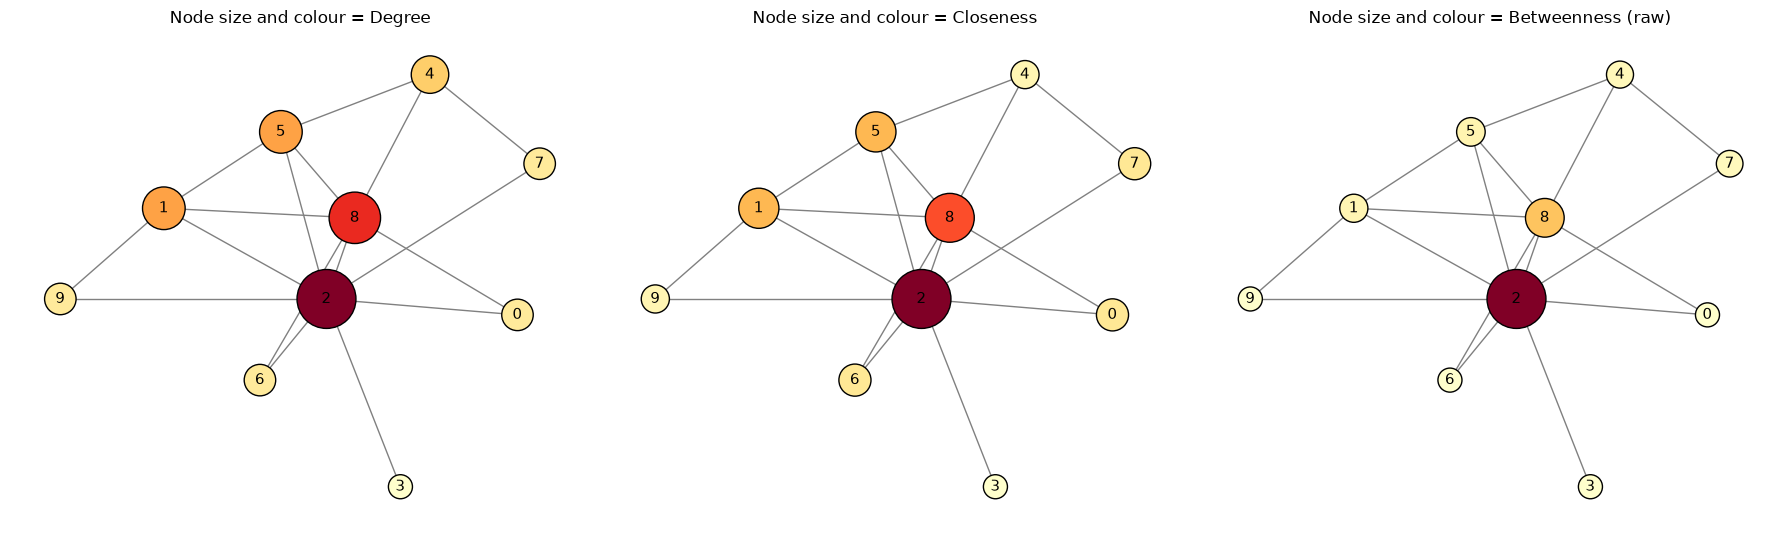

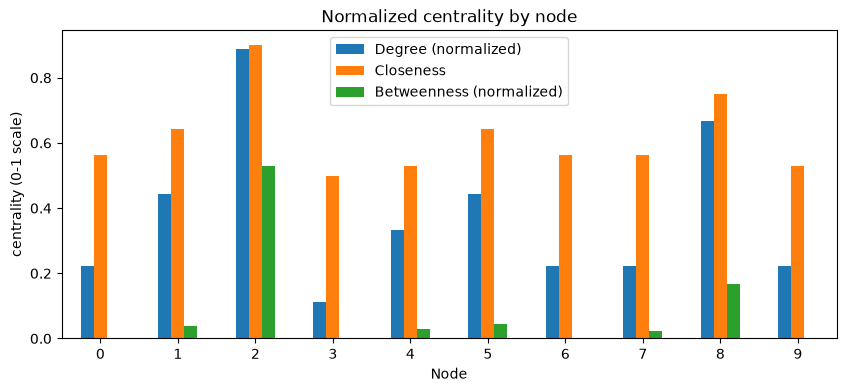

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (col, title) in zip(axes, [("Degree", "Degree"), ("Closeness", "Closeness"),
                                   ("Betweenness", "Betweenness (raw)")]):
    vals = table[col]
    nx.draw_networkx(G, POS, ax=ax, node_color=[vals[v] for v in G], cmap="YlOrRd",
                     node_size=[300 + 1500 * (vals[v] - vals.min()) / (vals.max() - vals.min() + 1e-9) for v in G],
                     edgecolors="black", font_size=11, edge_color="grey")
    ax.set_title(f"Node size and colour = {title}"); ax.axis("off")
plt.tight_layout(); plt.show()

table[["Degree (normalized)", "Closeness", "Betweenness (normalized)"]].plot.bar(figsize=(10, 4), rot=0)
plt.ylabel("centrality (0-1 scale)"); plt.title("Normalized centrality by node"); plt.show()

**Interpretation**
* **Node 2 is the hub on every measure.** It has degree 8 (linked to 8 of the 9 other nodes), the highest closeness (0.90: every node is at most 2 steps away) and the largest betweenness (19.1 of 36 possible pairs, 0.53 normalized). Removing it would cut node 3 off entirely and lengthen most paths.
* **Node 8 ranks second** (degree 6, closeness 0.75, betweenness 6.07). Nodes 1 and 5 are next (degree 4, closeness 0.64).
* **Node 3** is a leaf, with only one link (to 2), and has the lowest closeness (0.50). Nodes 0, 3, 6 and 9 have **zero betweenness**: no shortest path between two other nodes needs to go through them.
* **The measures do not always agree.** Node 7 has the same degree as nodes 0, 6 and 9 (degree 2), but it has positive betweenness (0.87). It lies on one of the **three equally short routes** from node 4 to node 2 (4-5-2, 4-8-2 and 4-7-2), so it earns 1/3 for the pair 4-2, 1/3 for 4-3 and 1/5 for 4-9 (0.87 in total). Degree measures local popularity, closeness measures reach, and betweenness measures brokerage.

---
## 4. My personal social network

> Draw your own personal "social network" and then remove your node from the network. After removing your node, which nodes rank highest in degree and closeness?

### 4.1 Building the network
I drew an **ego network**: me ("Bruno") plus the people I interact with regularly, grouped into five circles of my life, with an edge whenever two people know each other well. **Names are placeholders** (for privacy, and per the activity's intent). The *structure* reflects my real circles: family, university friends from Lima, my work team, my Purdue MS cohort, and my gym/sports group.

A few people **bridge** two circles, for example a work colleague who is also in the Purdue program, or a university friend who now works with me. These bridges are what keep the network connected once I am removed.

To try a different network, edit the dictionaries in the next cell; the rest of the notebook updates automatically.

In [10]:
ME = "Bruno"

GROUPS = {
    "Family":           ["Mom", "Dad", "Sister", "Partner"],
    "University (Lima)": ["Andrés", "Camila", "Diego", "Valeria"],
    "Work team":         ["Carla", "Jorge", "Lucía", "Martín", "Sebastián"],
    "Purdue MS cohort":  ["Priya", "Tom", "Ana", "Kevin"],
    "Gym / sports":      ["Rafa", "Nico"],
}

# Ties among my contacts (besides each one's tie to me)
TIES = [
    # family: everyone knows everyone
    ("Mom", "Dad"), ("Mom", "Sister"), ("Dad", "Sister"), ("Partner", "Sister"), ("Partner", "Mom"),
    # university friends
    ("Andrés", "Camila"), ("Andrés", "Diego"), ("Camila", "Valeria"), ("Diego", "Valeria"), ("Andrés", "Valeria"),
    # work team
    ("Carla", "Jorge"), ("Carla", "Lucía"), ("Jorge", "Martín"), ("Lucía", "Martín"),
    ("Carla", "Martín"), ("Sebastián", "Jorge"), ("Sebastián", "Lucía"),
    # Purdue cohort (online study group)
    ("Priya", "Tom"), ("Priya", "Ana"), ("Tom", "Kevin"), ("Ana", "Kevin"),
    # gym
    ("Rafa", "Nico"),
    # bridges between circles
    ("Lucía", "Ana"),        # colleague who is also in the Purdue program
    ("Diego", "Sebastián"),  # university friend who now works on my team
    ("Camila", "Partner"),   # university friend who is close to my partner
    ("Rafa", "Andrés"),      # gym buddy I met through a university friend
    ("Sister", "Valeria"),   # my sister and a university friend are friends
]

group_of = {p: g for g, people in GROUPS.items() for p in people}
group_of[ME] = "Me"

S = nx.Graph()
S.add_nodes_from(group_of)
S.add_edges_from((ME, p) for p in group_of if p != ME)   # I know everyone in my network
S.add_edges_from(TIES)
print(f"My network: {S.number_of_nodes()} people, {S.number_of_edges()} ties, density = {nx.density(S):.3f}")

My network: 20 people, 46 ties, density = 0.242


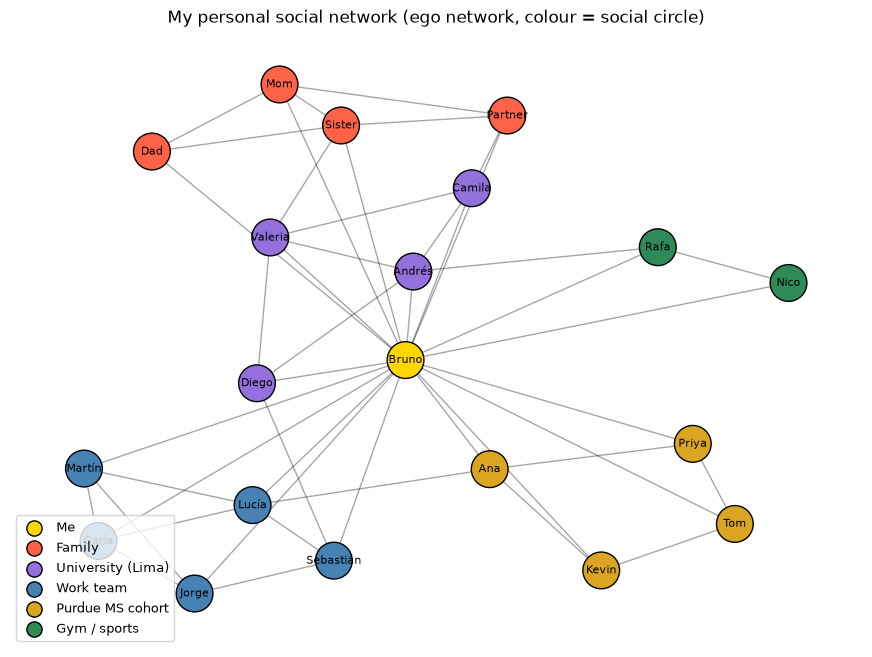

In [11]:
PALETTE = {"Me": "gold", "Family": "tomato", "University (Lima)": "mediumpurple", "Work team": "steelblue",
           "Purdue MS cohort": "goldenrod", "Gym / sports": "seagreen"}
LAYOUT = nx.spring_layout(S, seed=7, k=0.55)

def draw(graph, title, ax, size_by=None):
    sizes = [300 + 2200 * size_by[v] if size_by else 700 for v in graph]
    nx.draw_networkx_edges(graph, LAYOUT, ax=ax, alpha=.35)
    nx.draw_networkx_nodes(graph, LAYOUT, ax=ax, node_size=sizes, edgecolors="black",
                           node_color=[PALETTE[group_of[v]] for v in graph])
    nx.draw_networkx_labels(graph, LAYOUT, ax=ax, font_size=8)
    ax.set_title(title); ax.axis("off")

fig, ax = plt.subplots(figsize=(11, 8))
draw(S, "My personal social network (ego network, colour = social circle)", ax)
for g, c in PALETTE.items():
    ax.scatter([], [], c=c, s=120, edgecolors="black", label=g)
ax.legend(loc="lower left", fontsize=9)
plt.show()

### 4.2 Centrality *with* me in the network
As the ego, I am connected to everyone, so I trivially have the maximum degree, closeness (1.0) and betweenness. This is why the activity asks to remove the ego: it shows the network's *own* structure.

In [12]:
def centrality_table(graph):
    t = pd.DataFrame({
        "Group": {v: group_of[v] for v in graph},
        "Degree": dict(graph.degree()),
        "Degree (norm.)": nx.degree_centrality(graph),
        "Closeness": nx.closeness_centrality(graph),          # Wasserman-Faust scaling if disconnected
        "Betweenness (norm.)": nx.betweenness_centrality(graph),
    })
    return t.sort_values(["Degree", "Closeness"], ascending=False)

with_me = centrality_table(S)
with_me.head(8).round(3)

,Group,Degree,Degree (norm.),Closeness,Betweenness (norm.)
Bruno,Me,19,1.000,1.000,0.751
Sister,Family,5,0.263,0.576,0.010
Andrés,University (Lima),5,0.263,0.576,0.011
Valeria,University (Lima),5,0.263,0.576,0.010
Lucía,Work team,5,0.263,0.576,0.013
Mom,Family,4,0.211,0.559,0.002
Partner,Family,4,0.211,0.559,0.005
Camila,University (Lima),4,0.211,0.559,0.005


### 4.3 Removing my node

In [13]:
S_wo = S.copy()
S_wo.remove_node(ME)

comps = sorted(nx.connected_components(S_wo), key=len, reverse=True)
print(f"Without me: {S_wo.number_of_nodes()} people, {S_wo.number_of_edges()} ties, "
      f"{len(comps)} connected component(s)")
for i, c in enumerate(comps, 1):
    print(f"  component {i} ({len(c)} people): {sorted(c)}")
if nx.is_connected(S_wo):
    print(f"\nAverage shortest path: {nx.average_shortest_path_length(S):.2f} with me -> "
          f"{nx.average_shortest_path_length(S_wo):.2f} without me")
    print(f"Diameter (longest shortest path): {nx.diameter(S)} with me -> {nx.diameter(S_wo)} without me")

Without me: 19 people, 27 ties, 1 connected component(s)
  component 1 (19 people): ['Ana', 'Andrés', 'Camila', 'Carla', 'Dad', 'Diego', 'Jorge', 'Kevin', 'Lucía', 'Martín', 'Mom', 'Nico', 'Partner', 'Priya', 'Rafa', 'Sebastián', 'Sister', 'Tom', 'Valeria']

Average shortest path: 1.76 with me -> 3.70 without me
Diameter (longest shortest path): 2 with me -> 8 without me


**Note on closeness.** In my network the bridges keep everyone connected after I am removed (one component), so the standard closeness formula applies directly. In general, though, removing the ego often **splits** the network: if removing me splits the network, some pairs have no path between them, and the textbook formula breaks down (the distance would be infinite). `networkx` then uses the **Wasserman-Faust** correction:
$$C_{WF}(v) = \frac{r - 1}{n - 1}\cdot\frac{r - 1}{\sum_{u \in R(v)} d(v,u)}$$
where $R(v)$ is the set of $r$ nodes reachable from $v$ (including $v$). The first factor penalises nodes in small components, so a person in an isolated pair does not get an artificially perfect score. The table also reports **harmonic closeness**, $\sum_u 1/d(v,u)$ normalized by $n-1$, which handles disconnected graphs naturally (unreachable nodes contribute 0). Because it gives more weight to *nearby* nodes, harmonic closeness favours people with many direct friends (Valeria ranks first), whereas standard closeness favours people with short paths to *everyone*, including distant circles (Diego ranks first).

In [14]:
without_me = centrality_table(S_wo)
without_me["Harmonic closeness"] = pd.Series(nx.harmonic_centrality(S_wo)) / (S_wo.number_of_nodes() - 1)
without_me["Rank: degree"] = without_me["Degree"].rank(ascending=False, method="min").astype(int)
without_me["Rank: closeness"] = without_me["Closeness"].rank(ascending=False, method="min").astype(int)
without_me.round(3)

,Group,Degree,Degree (norm.),Closeness,Betweenness (norm.),Harmonic closeness,Rank: degree,Rank: closeness
Valeria,University (Lima),4,0.222,0.353,0.327,0.490,1,3
Andrés,University (Lima),4,0.222,0.346,0.264,0.481,1,4
Lucía,Work team,4,0.222,0.340,0.438,0.475,1,5
Sister,Family,4,0.222,0.290,0.206,0.444,1,7
Diego,University (Lima),3,0.167,0.383,0.529,0.474,5,1
Sebastián,Work team,3,0.167,0.375,0.534,0.468,5,2
Jorge,Work team,3,0.167,0.295,0.072,0.403,5,6
Camila,University (Lima),3,0.167,0.290,0.076,0.421,5,7
Ana,Purdue MS cohort,3,0.167,0.281,0.297,0.413,5,9
Carla,Work team,3,0.167,0.269,0.011,0.390,5,10


In [15]:
top_deg = without_me.sort_values(["Degree", "Closeness"], ascending=False).head(5)
top_clo = without_me.sort_values("Closeness", ascending=False).head(5)
print("Top 5 by DEGREE (without me):")
display(top_deg[["Group", "Degree", "Degree (norm.)"]].round(3))
print("Top 5 by CLOSENESS (without me):")
display(top_clo[["Group", "Closeness", "Harmonic closeness", "Betweenness (norm.)"]].round(3))

Top 5 by DEGREE (without me):


,Group,Degree,Degree (norm.)
Valeria,University (Lima),4,0.222
Andrés,University (Lima),4,0.222
Lucía,Work team,4,0.222
Sister,Family,4,0.222
Diego,University (Lima),3,0.167


Top 5 by CLOSENESS (without me):


,Group,Closeness,Harmonic closeness,Betweenness (norm.)
Diego,University (Lima),0.383,0.474,0.529
Sebastián,Work team,0.375,0.468,0.534
Valeria,University (Lima),0.353,0.490,0.327
Andrés,University (Lima),0.346,0.481,0.264
Lucía,Work team,0.340,0.475,0.438


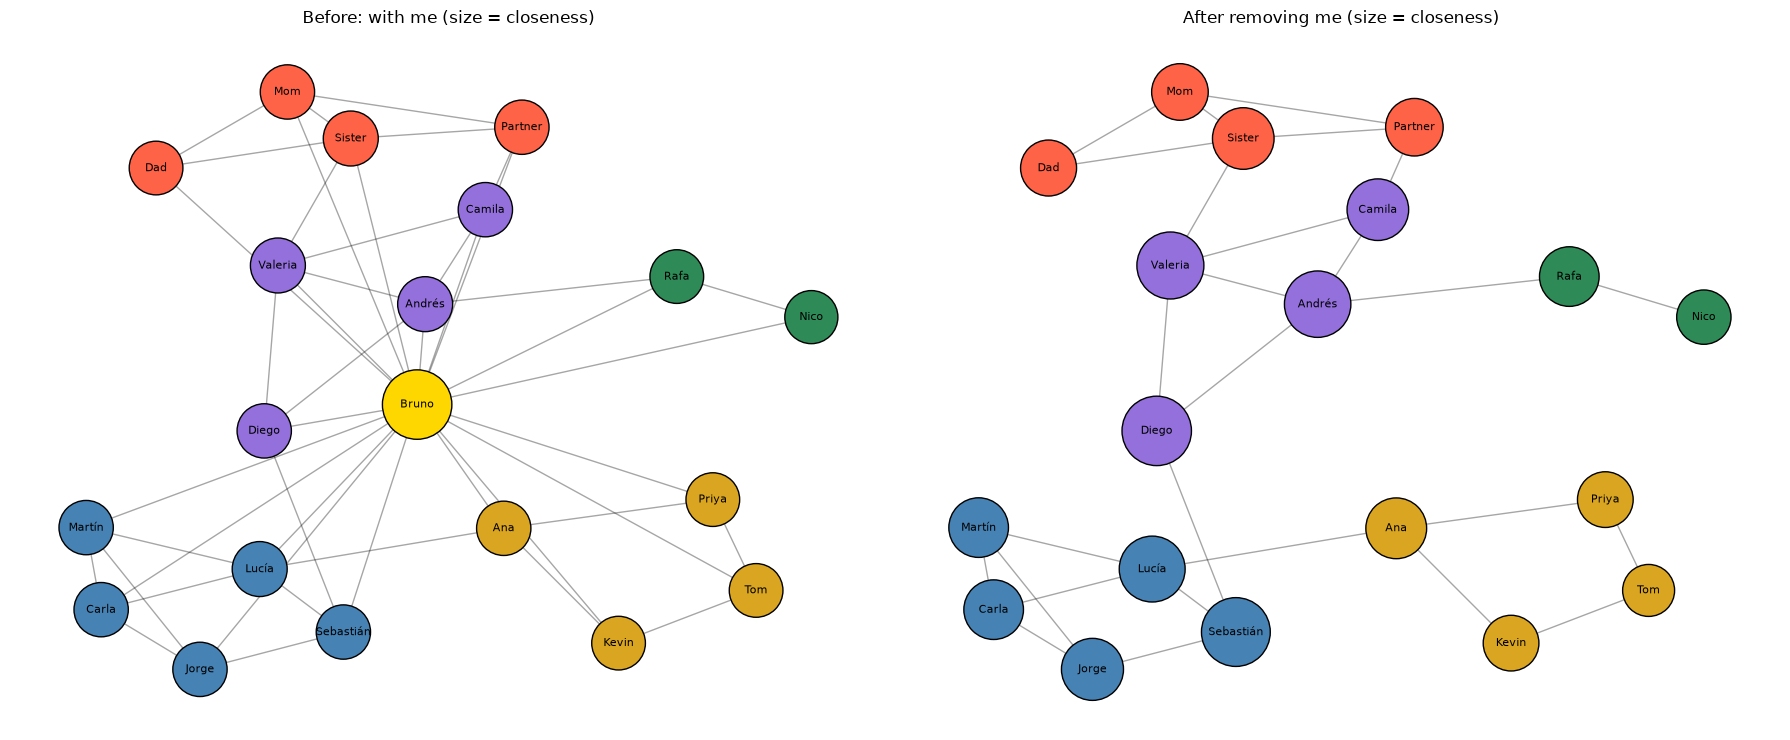

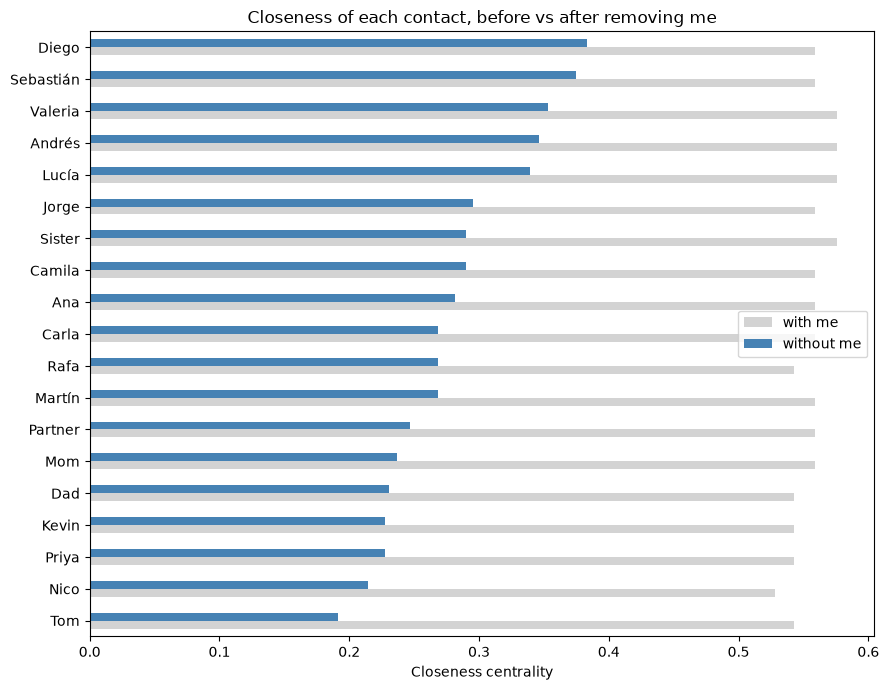

In [16]:
clo = nx.closeness_centrality(S_wo)
cmax = max(clo.values())
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
draw(S, "Before: with me (size = closeness)", axes[0], nx.closeness_centrality(S))
draw(S_wo, "After removing me (size = closeness)", axes[1], {v: c / cmax for v, c in clo.items()})
plt.tight_layout(); plt.show()

comp = pd.DataFrame({"with me": with_me["Closeness"].drop(ME), "without me": without_me["Closeness"]})
comp.sort_values("without me").plot.barh(figsize=(9, 7), color=["lightgrey", "steelblue"])
plt.xlabel("Closeness centrality"); plt.title("Closeness of each contact, before vs after removing me")
plt.tight_layout(); plt.show()

In [17]:
# Generate the written answer from the computed results
d1 = top_deg.index[0]
deg_top = top_deg[top_deg["Degree"] == top_deg["Degree"].iloc[0]].index.tolist()
clo_top = top_clo.index[:3].tolist()
print("Highest DEGREE after removing me:", ", ".join(f"{p} ({without_me.loc[p, 'Degree']})" for p in top_deg.index[:4]))
print("Highest CLOSENESS after removing me:", ", ".join(f"{p} ({without_me.loc[p, 'Closeness']:.3f})" for p in clo_top))

Highest DEGREE after removing me: Valeria (4), Andrés (4), Lucía (4), Sister (4)
Highest CLOSENESS after removing me: Diego (0.383), Sebastián (0.375), Valeria (0.353)


### 4.4 Answer

After removing my node, the 19 remaining people (27 ties) **stay in one connected network**, but only because of a few bridge relationships. The average distance between two people more than doubles, from **1.76 to 3.70 steps**, and the longest shortest path grows from **2 to 8**. With me in the network, everyone was at most two steps from everyone else, because they all went through me.

**Highest degree (number of direct ties):** **Valeria, Andrés, Lucía and Sister**, tied with **4 ties each**. Each is well connected *inside* their own circle and also has one tie to another circle: Valeria to my sister, Andrés to Rafa from the gym, Lucía to Ana in the Purdue cohort, and my sister to Valeria.

**Highest closeness (shortest average distance to everyone):** **Diego (0.383)** and **Sebastián (0.375)**, followed by Valeria (0.353), Andrés (0.346) and Lucía (0.340). Diego and Sebastián have only 3 ties each, but the tie between them, a university friend who now works on my team, connects the two largest circles (university and work). They sit in the middle of the network, so they can reach the family, gym and Purdue groups in fewer steps than anyone else. They also have the highest betweenness (≈ 0.53): most shortest paths between the two halves of my network go through them.

**What this shows**
* **Degree and closeness identify different kinds of importance.** Degree finds the most *popular* people within a circle. Closeness finds the best-positioned *connectors* between circles. In my network, these are different people.
* **My network depends on me.** Without me, the Purdue cohort is reachable only through Lucía–Ana, the gym group only through Rafa–Andrés, and my family only through Sister–Valeria and Partner–Camila. If any one of these ties were missing, my node would be a **cut vertex**, and removing it would split the network into separate groups. This is the typical structure of an ego network: the ego is the main broker between circles that otherwise barely interact.
* The same reasoning applies to the activity graph in Section 3, where node 2 plays the role I play here: removing it would cut off node 3 and lengthen most paths.